# Report figures and tables (whole group)

Makes the things the report needs that are not in the phase notebooks:
1. a **block diagram** of each member's pipeline + one for the whole group
2. a **group results table** (Phase 1 CNR, Phase 2 Dice/IoU, Phase 3 accuracy/F1/...) collected from everyone's output folders

Run it **after** everyone's 02/03/04 notebooks. Outputs go to `report/figures/` and `report/group_results.csv`.

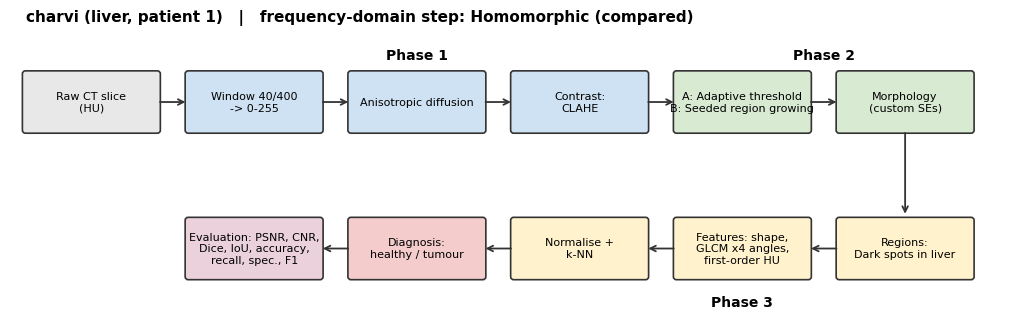

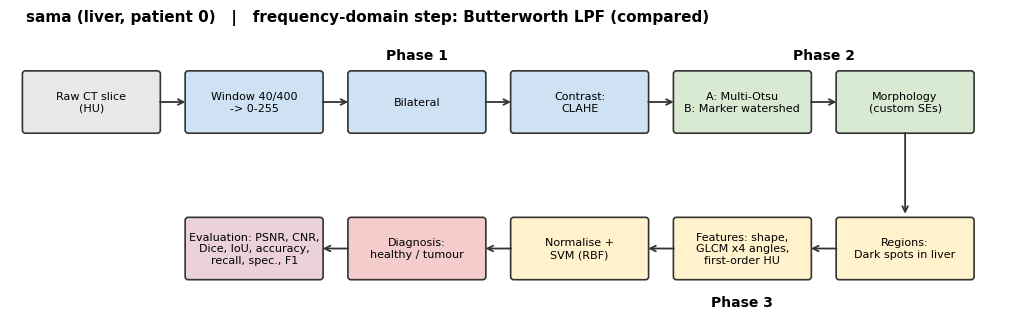

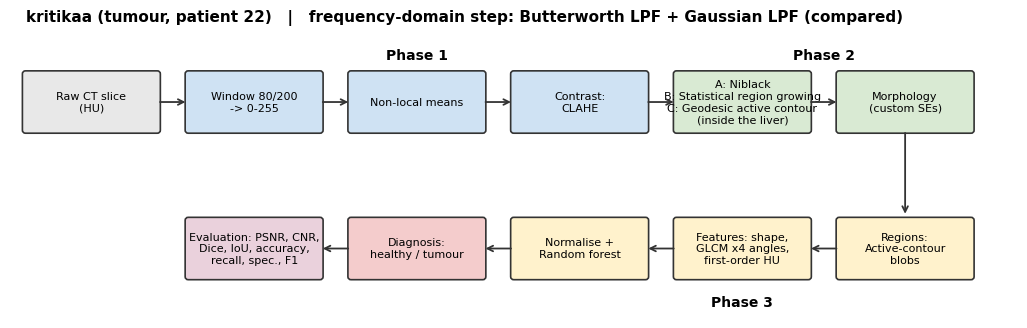

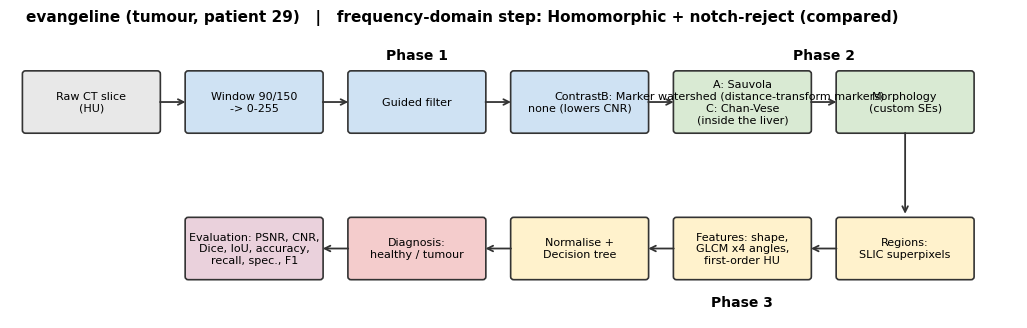

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

MEMBERS = {
    "charvi":     {"organ": "liver",  "patient": 1,  "window": "Window 40/400", "filter": "Anisotropic diffusion",
                   "contrast": "CLAHE", "frequency": "Homomorphic (compared)", "segA": "Adaptive threshold",
                   "segB": "Seeded region growing", "keys": ["adaptive", "regiongrow"], "best": "regiongrow", "regions": "Dark spots in liver", "clf": "k-NN"},
    "sama":       {"organ": "liver",  "patient": 0,  "window": "Window 40/400", "filter": "Bilateral",
                   "contrast": "CLAHE", "frequency": "Butterworth LPF (compared)", "segA": "Multi-Otsu",
                   "segB": "Marker watershed", "keys": ["multiotsu", "watershed"], "best": "watershed", "regions": "Dark spots in liver", "clf": "SVM (RBF)"},
    "kritikaa":   {"organ": "tumour", "patient": 22, "window": "Window 80/200", "filter": "Non-local means",
                   "contrast": "CLAHE", "frequency": "Butterworth LPF + Gaussian LPF (compared)", "segA": "Niblack",
                   "segB": "Statistical region growing", "segC": "Geodesic active contour", "keys": ["niblack", "regiongrow", "gac"],
                   "best": "gac", "regions": "Active-contour\nblobs", "clf": "Random forest"},
    "evangeline": {"organ": "tumour", "patient": 29, "window": "Window 90/150", "filter": "Guided filter",
                   "contrast": "none (lowers CNR)", "frequency": "Homomorphic + notch-reject (compared)", "segA": "Sauvola",
                   "segB": "Marker watershed (distance-transform markers)", "segC": "Chan-Vese",
                   "keys": ["sauvola", "watershed", "chanvese"], "best": "sauvola", "regions": "SLIC superpixels", "clf": "Decision tree"},
}
FIGS = "figures"
os.makedirs(FIGS, exist_ok=True)

def box(ax, x, y, text, colour, w=1.7, h=0.75):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=colour, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8)

def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3, color="#333333"))

def pipeline_diagram(name, m, path):
    fig, ax = plt.subplots(figsize=(13, 4.0))
    ax.set_xlim(0, 13); ax.set_ylim(0, 4.1); ax.axis("off")
    top = [("Raw CT slice\n(HU)", "#e8e8e8"), (m["window"] + "\n-> 0-255", "#cfe2f3"), (m["filter"], "#cfe2f3"),
           ("Contrast:\n" + m["contrast"], "#cfe2f3"), (f"A: {m['segA']}\nB: {m['segB']}" + (f"\nC: {m['segC']}" if "segC" in m else "") + ("\n(inside the liver)" if m["organ"] == "tumour" else ""), "#d9ead3"),
           ("Morphology\n(custom SEs)", "#d9ead3")]
    bottom = [("Regions:\n" + m["regions"], "#fff2cc"), ("Features: shape,\nGLCM x4 angles,\nfirst-order HU", "#fff2cc"),
              ("Normalise +\n" + m["clf"], "#fff2cc"), ("Diagnosis:\nhealthy / tumour", "#f4cccc"),
              ("Evaluation: PSNR, CNR,\nDice, IoU, accuracy,\nrecall, spec., F1", "#ead1dc")]
    for i, (t, c) in enumerate(top):
        box(ax, 0.2 + i * 2.1, 2.5, t, c)
        if i:
            arrow(ax, 0.2 + i * 2.1 - 0.4, 2.875, 0.2 + i * 2.1, 2.875)
    ax.text(0.2 + 2 * 2.1 + 0.85, 3.45, "Phase 1", ha="center", fontsize=10, weight="bold")
    ax.text(0.2 + 4.5 * 2.1 + 0.85, 3.45, "Phase 2", ha="center", fontsize=10, weight="bold")
    arrow(ax, 0.2 + 5 * 2.1 + 0.85, 2.5, 0.2 + 5 * 2.1 + 0.85, 1.35)
    for i, (t, c) in enumerate(bottom):
        x = 0.2 + (5 - i) * 2.1 - (0 if i else 0)
        box(ax, x, 0.55, t, c)
        if i:
            arrow(ax, x + 2.1, 0.925, x + 1.7, 0.925)
    ax.text(0.2 + 4 * 2.1 + 0.85, 0.15, "Phase 3", ha="center", fontsize=10, weight="bold")
    ax.text(0.2, 3.95, f"{name} ({m['organ']}, patient {m['patient']})   |   frequency-domain step: {m['frequency']}", fontsize=11, weight="bold")
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.show()

for name, m in MEMBERS.items():
    os.makedirs(f"{FIGS}/{name}", exist_ok=True)
    pipeline_diagram(name, m, f"{FIGS}/{name}/{name}_pipeline_diagram.png")

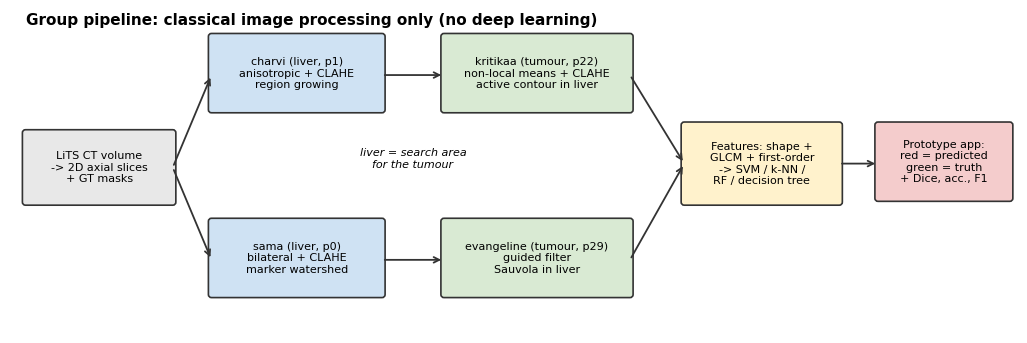

In [2]:
# group overview diagram: liver members find the liver, tumour members search inside it, everyone classifies regions
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis("off")
box(ax, 0.2, 1.7, "LiTS CT volume\n-> 2D axial slices\n+ GT masks", "#e8e8e8", w=1.9, h=0.9)
box(ax, 2.6, 2.9, "charvi (liver, p1)\nanisotropic + CLAHE\nregion growing", "#cfe2f3", w=2.2, h=0.95)
box(ax, 2.6, 0.5, "sama (liver, p0)\nbilateral + CLAHE\nmarker watershed", "#cfe2f3", w=2.2, h=0.95)
box(ax, 5.6, 2.9, "kritikaa (tumour, p22)\nnon-local means + CLAHE\nactive contour in liver", "#d9ead3", w=2.4, h=0.95)
box(ax, 5.6, 0.5, "evangeline (tumour, p29)\nguided filter\nSauvola in liver", "#d9ead3", w=2.4, h=0.95)
box(ax, 8.7, 1.7, "Features: shape +\nGLCM + first-order\n-> SVM / k-NN /\nRF / decision tree", "#fff2cc", w=2.0, h=1.0)
box(ax, 11.2, 1.75, "Prototype app:\nred = predicted\ngreen = truth\n+ Dice, acc., F1", "#f4cccc", w=1.7, h=0.95)
for y in (3.35, 0.95):
    arrow(ax, 2.1, 2.15, 2.6, y)
arrow(ax, 4.8, 3.35, 5.6, 3.35); arrow(ax, 4.8, 0.95, 5.6, 0.95)
ax.text(5.2, 2.15, "liver = search area\nfor the tumour", ha="center", fontsize=8, style="italic")
for y in (3.35, 0.95):
    arrow(ax, 8.0, y, 8.7, 2.2)
arrow(ax, 10.7, 2.2, 11.2, 2.2)
ax.text(0.2, 4.0, "Group pipeline: classical image processing only (no deep learning)", fontsize=11, weight="bold")
plt.savefig(f"{FIGS}/group_pipeline_diagram.png", dpi=130, bbox_inches="tight"); plt.show()

In [3]:
def predicted_liver_dice(name, method, area="predicted liver"):
    """Tumour members: final-method Dice when the search area is found automatically (no ground-truth liver)."""
    p = f"../phase2/outputs_{name}/phase2_metrics_predicted_liver.csv"
    if not os.path.exists(p):
        return None
    d = pd.read_csv(p)
    return round(d[(d.method == method) & (d["search area"] == area)]["Dice"].mean(), 3)

rows = []
for name, m in MEMBERS.items():
    p1 = pd.read_csv(f"../phase1/outputs_{name}/phase1_metrics.csv")
    p2 = pd.read_csv(f"../phase2/outputs_{name}/phase2_metrics.csv")
    p3 = pd.read_csv(f"../phase3/outputs_{name}/phase3_metrics.csv").iloc[0]
    p1m = p1.groupby("method").mean(numeric_only=True)
    seg = p2.groupby("method")[["Dice", "IoU"]].mean()
    rows.append({"member": name, "organ": m["organ"], "patient": m["patient"],
                 "best Phase 1 tumour CNR": p1m["CNR tumour vs liver"].max().round(2),
                 **{f"Phase 2 method {L}": m.get(f"seg{L}", "") for L in "ABC"},
                 **{f"Dice {L}": (seg.loc[k, "Dice"].round(3) if k in seg.index else None) for L, k in zip("ABC", m["keys"] + [None] * 3)},
                 "final method": m["best"], "Dice (final)": seg.loc[m["best"], "Dice"].round(3),
                 "IoU (final)": seg.loc[m["best"], "IoU"].round(3),
                 "tumour Dice, predicted liver": predicted_liver_dice(name, m["best"]),
                 "tumour Dice, convex hull of predicted liver": predicted_liver_dice(name, m["best"], "convex hull of predicted liver"), "classifier": m["clf"],
                 "tuned (grouped 5-fold CV)": ", ".join((f"{k[6:]} = None" if pd.isna(p3[k]) else f"{k[6:]} = {p3[k]:g}") for k in p3.index if k.startswith("tuned")),
                 "CV F1 (mean +/- std)": f"{p3['CV F1 mean']:.3f} +/- {p3['CV F1 std']:.3f}",
                 "accuracy": round(p3["accuracy"], 3),
                 "accuracy 95% CI": f"[{p3['accuracy CI low']:.2f}, {p3['accuracy CI high']:.2f}]", "sensitivity": round(p3["sensitivity (recall)"], 3),
                 "specificity": round(p3["specificity"], 3), "F1": round(p3["F1"], 3),
                 "F1 95% CI": f"[{p3['F1 CI low']:.2f}, {p3['F1 CI high']:.2f}]"})
group = pd.DataFrame(rows)
group.to_csv("group_results.csv", index=False)

print(group.to_string(index=False))

    member  organ  patient  best Phase 1 tumour CNR   Phase 2 method A                              Phase 2 method B        Phase 2 method C  Dice A  Dice B  Dice C final method  Dice (final)  IoU (final)  tumour Dice, predicted liver  tumour Dice, convex hull of predicted liver    classifier tuned (grouped 5-fold CV) CV F1 (mean +/- std)  accuracy accuracy 95% CI  sensitivity  specificity    F1    F1 95% CI
    charvi  liver        1                     1.92 Adaptive threshold                         Seeded region growing                           0.756   0.886     NaN   regiongrow         0.886        0.836                           NaN                                          NaN          k-NN                     k = 5      0.743 +/- 0.143     0.886    [0.88, 0.91]        0.500        0.972 0.615 [0.50, 0.67]
      sama  liver        0                     1.35         Multi-Otsu                              Marker watershed                           0.795   0.914     NaN    watershe

**Group comparison.** Per-slice Dice of every Phase 2 method; a paired Wilcoxon signed-rank test checks whether each member's final method beats each alternative on the same slices (no normal distribution needed).

    member  organ final method compared with  slices final mean +/- std other mean +/- std  final better on (slices)  Wilcoxon p  significant (p < 0.05)
    charvi  liver   regiongrow      adaptive      18    0.886 +/- 0.224    0.756 +/- 0.204                        17      0.0000                    True
      sama  liver    watershed     multiotsu      16    0.914 +/- 0.077    0.795 +/- 0.224                        14      0.0063                    True
  kritikaa tumour          gac       niblack      12    0.707 +/- 0.268    0.594 +/- 0.248                        11      0.0015                    True
  kritikaa tumour          gac    regiongrow      12    0.707 +/- 0.268    0.648 +/- 0.288                         7      0.1294                   False
evangeline tumour      sauvola     watershed      22    0.638 +/- 0.227    0.458 +/- 0.342                        15      0.0137                    True
evangeline tumour      sauvola      chanvese      22    0.638 +/- 0.227    0.608 +

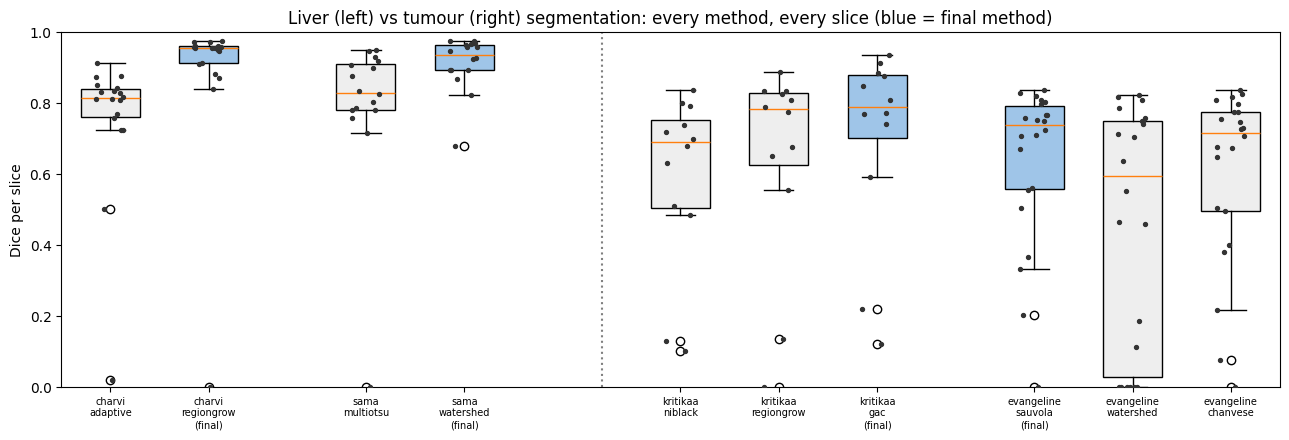

In [4]:
# ---- group comparison: per-slice Dice of every method, paired Wilcoxon test final vs each alternative ----
import numpy as np
from scipy.stats import wilcoxon

tests, per_slice = [], []
for name, m in MEMBERS.items():
    p2 = pd.read_csv(f"../phase2/outputs_{name}/phase2_metrics.csv")
    wide = p2.pivot(index="slice", columns="method", values="Dice")
    for key in m["keys"]:
        per_slice += [{"member": name, "organ": m["organ"], "method": key, "final": key == m["best"], "Dice": d} for d in wide[key]]
        if key == m["best"]:
            continue
        diff = wide[m["best"]] - wide[key]
        p = wilcoxon(wide[m["best"]], wide[key]).pvalue if (diff != 0).any() else 1.0
        tests.append({"member": name, "organ": m["organ"], "final method": m["best"], "compared with": key,
                      "slices": len(wide), "final mean +/- std": f"{wide[m['best']].mean():.3f} +/- {wide[m['best']].std():.3f}",
                      "other mean +/- std": f"{wide[key].mean():.3f} +/- {wide[key].std():.3f}",
                      "final better on (slices)": int((diff > 0).sum()), "Wilcoxon p": round(p, 4),
                      "significant (p < 0.05)": p < 0.05})
tests = pd.DataFrame(tests)
tests.to_csv("group_method_tests.csv", index=False)
print(tests.to_string(index=False))

per_slice = pd.DataFrame(per_slice)
fig, ax = plt.subplots(figsize=(13, 4.5))
pos, ticks, labels = 0, [], []
for organ in ["liver", "tumour"]:
    for name in [n for n, m in MEMBERS.items() if m["organ"] == organ]:
        for key in MEMBERS[name]["keys"]:
            d = per_slice[(per_slice.member == name) & (per_slice.method == key)]["Dice"]
            final = key == MEMBERS[name]["best"]
            ax.boxplot(d, positions=[pos], widths=0.6, patch_artist=True,
                       boxprops=dict(facecolor="#9fc5e8" if final else "#eeeeee"))
            ax.scatter(np.full(len(d), pos) + np.random.default_rng(0).uniform(-0.15, 0.15, len(d)), d, s=8, color="#333333", zorder=3)
            ticks.append(pos); labels.append(f"{name}\n{key}" + ("\n(final)" if final else "")); pos += 1
        pos += 0.6
    pos += 0.6
ax.set_xticks(ticks, labels, fontsize=7); ax.set_ylabel("Dice per slice"); ax.set_ylim(0, 1)
ax.axvline(sum(len(MEMBERS[n]["keys"]) for n, m in MEMBERS.items() if m["organ"] == "liver") + 1.0, color="grey", linestyle=":")
ax.set_title("Liver (left) vs tumour (right) segmentation: every method, every slice (blue = final method)")
plt.tight_layout(); plt.savefig(f"{FIGS}/group_dice_comparison.png", dpi=130); plt.show()